In [181]:
import rawpy
import sys
import os
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio
import tifffile

imageFolder = Path("images")
helperFolder = Path("../helper")
if str(helperFolder.resolve()) not in sys.path:
    sys.path.insert(0, str(helperFolder.resolve()))

import utils
import psu_imaging as psu
importlib.reload(utils)
importlib.reload(psu)

<module 'psu_imaging' from 'C:\\Users\\EMMWILL\\repos\\EE513\\exercises\\helper\\psu_imaging.py'>

## Part 1

### D1

In [ ]:
allImagePaths = list(imageFolder.glob("*.DNG"))
varyingLightPaths = sorted(
    (imagePath for imagePath in allImagePaths if ("dark" not in imagePath.stem.lower()) and ('cb' not in imagePath.stem.lower())),
    key=lambda imagePath: (int(imagePath.stem[:-1]), imagePath.stem[-1].lower()),
)

varyingLightSheet = utils.create_contact_sheet(
    varyingLightPaths,
    columns=4,
    outputPath=imageFolder / "d1.png",
)
# darkSheet = utils.create_contact_sheet(
#     darkImagePaths,
#     columns=5,
#     outputPath=imageFolder / "d1_dark.png",
# )
# display(varyingLightSheet)
# display(darkSheet)



imagePathsA = sorted(
    (p for p in imageFolder.glob("*.DNG")
     if p.stem.endswith("a") and p.stem[:-1].isdigit()),
    key=lambda p: int(p.stem[:-1]),
)

exposureTimesSeconds = []
for imagePath in imagePathsA:
    with tifffile.TiffFile(imagePath) as dng:
        numerator, denominator = (
            dng.pages[0].tags["ExifTag"].value["ExposureTime"]
        )
    exposureSeconds = numerator / denominator
    exposureTimesSeconds.append(exposureSeconds)
    print(f"{imagePath.name}: {exposureSeconds:.6f} s")

### D2

In [158]:
ids = {psu.lens_id(f) for f in varyingLightPaths}
assert len(ids) == 1, f"more than one camera in this series: {ids}"
print(ids)

{('iPhone 16 back camera 5.96mm f/1.6', 5.96, 26, (4224, 3024))}


### D3

In [19]:
darkImagePaths = sorted(
    (imagePath for imagePath in allImagePaths if "dark" in imagePath.stem.lower()),
    key=lambda imagePath: imagePath.stem.lower(),
)

for image in darkImagePaths:
    with rawpy.imread(str(image)) as raw:
        #find the black level per channel
        blackLevels = raw.black_level_per_channel
        print(f"{image.stem}: {blackLevels}")

dark1: [528, 528, 528, 528]
dark2: [528, 528, 528, 528]
dark3: [528, 528, 528, 528]
dark4: [528, 528, 528, 528]
dark5: [528, 528, 528, 528]
dark5: [528, 528, 528, 528]
dark5: Mean Black Level = 528.0


In [20]:
with rawpy.imread(str(darkImagePaths[4])) as raw:
    frameMeanDN = float(np.mean(raw.raw_image_visible))
    print(frameMeanDN)

527.7251521557697


## Part 2

### D4

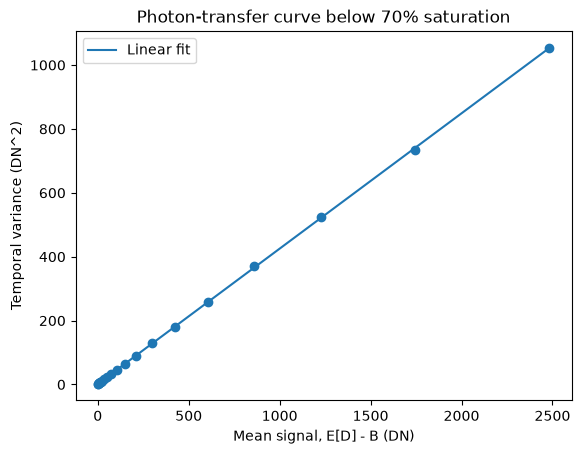

truth:  read noise = 2.80 e-; helper: read noise = 2.96 e-
conversion gain: truth = 2.344 e-/DN; helper = 2.361 e-/DN
Read Noise error:  -5.71843121429827 %
Conversion Gain error:  -0.6887201849093656 %


In [160]:
PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor


def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)


levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(electrons, index) for index, electrons in enumerate(levels)]

importlib.reload(utils)
helperMeanDN, helperVarianceDN2 = utils.measure_flat_field_pairs(
    pairs,
    psu.BLACK_LEVEL,
    roiSize=128,
)
fitResults = utils.plot_photon_transfer(
    helperMeanDN,
    helperVarianceDN2,
    saturationDN=psu.WHITE_LEVEL - psu.BLACK_LEVEL,
)
plt.show()

trueGainDNPerElectron = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL
trueReadNoiseElectrons = psu.READ_NOISE
trueInterceptDN2 = trueGainDNPerElectron ** 2 * trueReadNoiseElectrons ** 2
trueConversionGainElectronPerDN = 1 / trueGainDNPerElectron


print(
    f"truth:  read noise = {trueReadNoiseElectrons:.2f} e-; "
    f"helper: read noise = {fitResults['readNoiseElectrons']:.2f} e-"
)
print(
    f"conversion gain: truth = {trueConversionGainElectronPerDN:.3f} e-/DN; "
    f"helper = {fitResults['conversionGainElectronPerDN']:.3f} e-/DN"
)
print('Read Noise error: ', 100 * (trueReadNoiseElectrons - fitResults['readNoiseElectrons'])/trueReadNoiseElectrons, '%')
print('Conversion Gain error: ', 100 * (trueConversionGainElectronPerDN - fitResults['conversionGainElectronPerDN'])/trueConversionGainElectronPerDN, '%')


### D5

In [ ]:

imagePairs = list(zip(varyingLightPaths[::2], varyingLightPaths[1::2]))
with rawpy.imread(str(varyingLightPaths[0])) as raw:
    blackLevelDN = float(np.mean(raw.black_level_per_channel))

meanSignalDN, noiseVarianceDN2 = utils.measure_flat_field_pairs(
    imagePairs,
    blackLevelDN,
    roiSize=128,
)

In [92]:
imagePairs = list(zip(varyingLightPaths[::2], varyingLightPaths[1::2]))
with rawpy.imread(str(varyingLightPaths[0])) as raw:
    blackLevelDN = float(np.mean(raw.black_level_per_channel))
    saturationDN = float(raw.white_level - blackLevelDN)

meanSignalDNPair, noiseVarianceDN2Pair = utils.measure_flat_field_pairs(
    imagePairs,
    blackLevelDN,
    roiSize=128,
)

meanSignalDNPair = np.delete(meanSignalDNPair, 7)
noiseVarianceDN2Pair = np.delete(noiseVarianceDN2Pair, 7)

In [94]:
for i, item in enumerate(meanSignalDNPair):
    print(f"Image {i}:\t  Mean Signal DN: {item:.3f}\t Noise Variance DN^2: {noiseVarianceDN2[i]:.3f} \t Pixel Count: {128*128}")

Image 0:	  Mean Signal DN: 105.409	 Noise Variance DN^2: 31.055 	 Pixel Count: 16384
Image 1:	  Mean Signal DN: 161.205	 Noise Variance DN^2: 42.669 	 Pixel Count: 16384
Image 2:	  Mean Signal DN: 243.257	 Noise Variance DN^2: 64.115 	 Pixel Count: 16384
Image 3:	  Mean Signal DN: 491.156	 Noise Variance DN^2: 140.927 	 Pixel Count: 16384
Image 4:	  Mean Signal DN: 616.138	 Noise Variance DN^2: 173.874 	 Pixel Count: 16384
Image 5:	  Mean Signal DN: 994.486	 Noise Variance DN^2: 312.630 	 Pixel Count: 16384
Image 6:	  Mean Signal DN: 1668.935	 Noise Variance DN^2: 570.778 	 Pixel Count: 16384
Image 7:	  Mean Signal DN: 3551.665	 Noise Variance DN^2: 1037.932 	 Pixel Count: 16384
Image 8:	  Mean Signal DN: 3551.472	 Noise Variance DN^2: 289.098 	 Pixel Count: 16384
Image 9:	  Mean Signal DN: 15.013	 Noise Variance DN^2: 285.891 	 Pixel Count: 16384


### D6

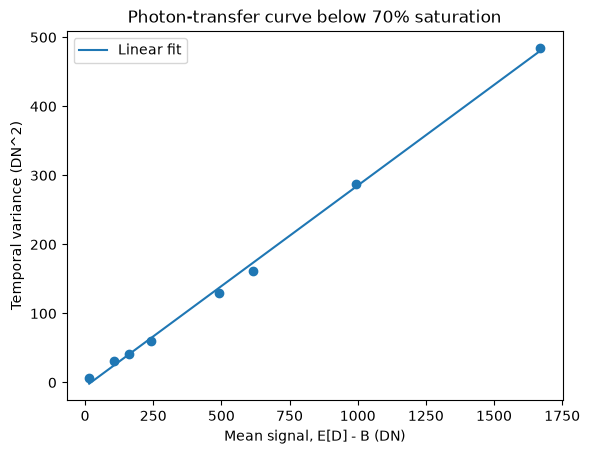

Fit points: (15.012542724609375, 1668.9347839355469) DN
Plotted through: 2496.9 DN
Slope/Conversion Gain: 0.29140114580159326 DN/electron
Intercept: -6.1211732404092585 DN^2
Read noise: 8.490359515795703 i DN


In [174]:
importlib.reload(utils)

#remove results from image 7


fitResultsPair = utils.plot_photon_transfer(
    meanSignalDNPair,
    noiseVarianceDN2Pair,
    saturationDN=saturationDN,
    # fitRange=(50, 1200),
)
plt.savefig('images/d6a.png')
plt.show()
print(f"Fit points: {fitResultsPair['fitRangeDN']} DN")
print(f"Plotted through: {fitResultsPair['saturationLimitDN']:.1f} DN")
print(f"Slope/Conversion Gain: {fitResultsPair['slopeDNPerElectron']} DN/electron")
print(f"Intercept: {fitResultsPair['interceptDN2']} DN^2")
if(fitResultsPair['interceptDN2'] < 0):
    print(f"Read noise: {np.sqrt(abs(fitResultsPair['interceptDN2'])/fitResultsPair['slopeDNPerElectron']**2)} i DN")
else:
    print(f"Read noise: {np.sqrt(fitResultsPair['interceptDN2']/fitResultsPair['slopeDNPerElectron']**2)} DN")

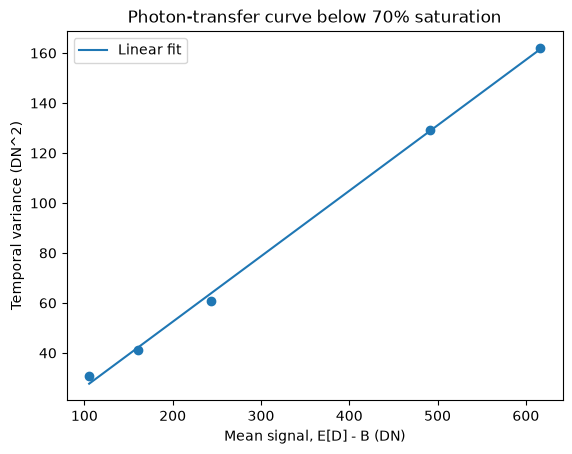

Fit points: (105.40899658203125, 616.1381225585938) DN
Plotted through: 2496.9 DN
Slope/Conversion Gain: 0.2619961559823211 DN/electron
Intercept: 0.0677843420591741 DN^2
Read noise: 0.9937331394569178 DN


In [175]:
a = 0
b = 5
fitResultsPair = utils.plot_photon_transfer(
    meanSignalDNPair[a:b],
    noiseVarianceDN2Pair[a:b],
    saturationDN=saturationDN,
    # fitRange=(50, 1200),
)
plt.savefig('images/d6b.png')
plt.show()
print(f"Fit points: {fitResultsPair['fitRangeDN']} DN")
print(f"Plotted through: {fitResultsPair['saturationLimitDN']:.1f} DN")
print(f"Slope/Conversion Gain: {fitResultsPair['slopeDNPerElectron']} DN/electron")
print(f"Intercept: {fitResultsPair['interceptDN2']} DN^2")
if(fitResultsPair['interceptDN2'] < 0):
    print(f"Read noise: {np.sqrt(abs(fitResultsPair['interceptDN2'])/fitResultsPair['slopeDNPerElectron']**2)} i DN")
else:
    print(f"Read noise: {np.sqrt(fitResultsPair['interceptDN2']/fitResultsPair['slopeDNPerElectron']**2)} DN")

### D7

In [96]:
singleImagePaths = varyingLightPaths[::2]

meanSignalDNSingle, noiseVarianceDN2Single = utils.measure_flat_field_single(
    singleImagePaths,
    blackLevelDN,
    roiSize=128,
)

C:\Users\EMMWILL\repos\EE513\exercises\helper\utils.py:413: RuntimeWarning: invalid value encountered in sqrt
  return {


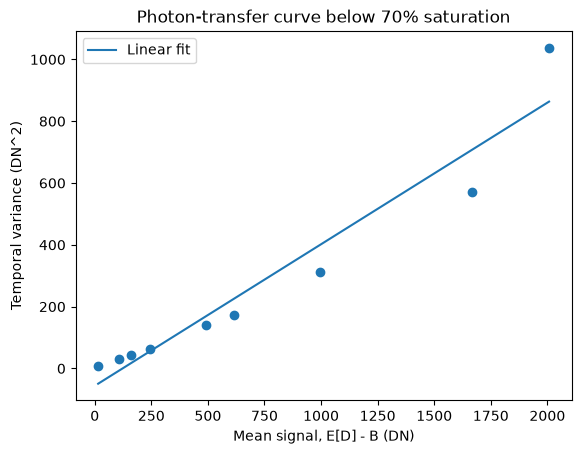

Slope/Conversion Gain For Single Image: 0.4581630783558368 DN/electron
Slope/Conversion Gain For Pair Image: 0.2619961559823211 DN/electron
Relative Error: 75.25%


In [ ]:
fitResultsSingle = utils.plot_photon_transfer(
    meanSignalDNSingle,
    noiseVarianceDN2Single,
    saturationDN=saturationDN,
    # fitRange=(50, 1200),
)
plt.savefig("images/d7.png")
plt.show()

print(f"Slope/Conversion Gain For Single Image: {fitResultsSingle['slopeDNPerElectron']} DN/electron")
print(f"Slope/Conversion Gain For Pair Image: {fitResultsPair['slopeDNPerElectron']} DN/electron")
print(f"Relative Error: {abs(fitResultsSingle['slopeDNPerElectron'] - fitResultsPair['slopeDNPerElectron']) / fitResultsPair['slopeDNPerElectron'] * 100:.2f}%")

### D8

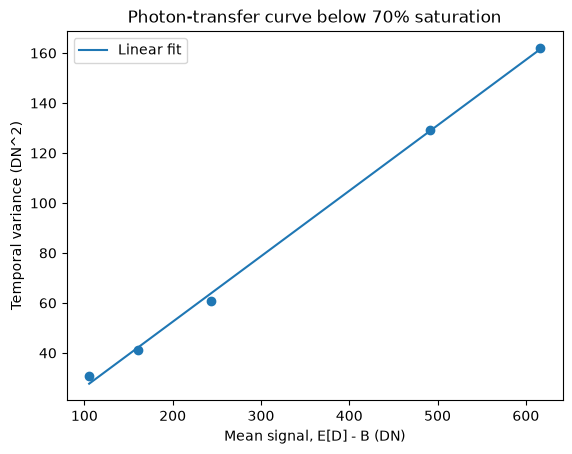

RAW saturation range: 3567.0 DN
Fit range: 105.4 to 616.1 DN
Fitted slope: 0.2620 DN/e-
Estimated full-well capacity: 13615 e-
Dynamic-range low-end convention: one RMS read-noise level (SNR = 1).
Estimated read noise: 0.99 e-
Estimated dynamic range: 13.74 stops


In [177]:
# Fit the visibly linear low-signal region; all <70% points remain plotted.
# readNoiseFitRangeDN = (50, 500)
# reportFitResults = utils.plot_photon_transfer(
#     meanSignalDNPair,
#     noiseVarianceDN2Pair,
#     saturationDN=saturationDN,
#     fitRange=readNoiseFitRangeDN,
# )

a = 0
b = 5
reportFitResults = utils.plot_photon_transfer(
    meanSignalDNPair[a:b],
    noiseVarianceDN2Pair[a:b],
    saturationDN=saturationDN,
    # fitRange=(50, 1200),
)
plt.show()

fitSlopeDNPerElectron = reportFitResults["slopeDNPerElectron"]
fullWellCapacityElectrons = saturationDN / fitSlopeDNPerElectron
print(f"RAW saturation range: {saturationDN:.1f} DN")
print(f"Fit range: {reportFitResults['fitRangeDN'][0]:.1f} to "
      f"{reportFitResults['fitRangeDN'][1]:.1f} DN")
print(f"Fitted slope: {fitSlopeDNPerElectron:.4f} DN/e-")
print(f"Estimated full-well capacity: {fullWellCapacityElectrons:.0f} e-")

# Dynamic-range convention: lower limit is one RMS read-noise level (SNR = 1).
print("Dynamic-range low-end convention: one RMS read-noise level (SNR = 1).")
if reportFitResults["interceptDN2"] > 0:
    readNoiseElectrons = (
        np.sqrt(reportFitResults["interceptDN2"]) / fitSlopeDNPerElectron
    )
    dynamicRangeStops = np.log2(fullWellCapacityElectrons / readNoiseElectrons)
    print(f"Estimated read noise: {readNoiseElectrons:.2f} e-")
    print(f"Estimated dynamic range: {dynamicRangeStops:.2f} stops")
else:
    print(
        "Dynamic range unavailable: the selected fit has a nonpositive "
        "intercept, so it does not give a physical read-noise estimate."
    )

## Part 3

### D9

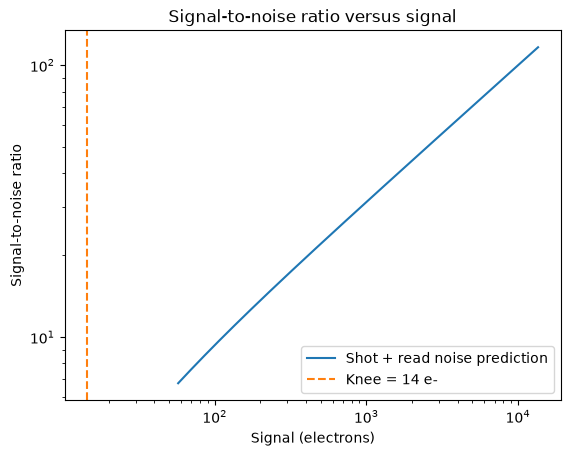

Knee signal: 14.39 electrons


In [182]:
signalElectrons = (
    meanSignalDNPair * reportFitResults["conversionGainElectronPerDN"]
)
readNoiseElectrons = reportFitResults["readNoiseElectrons"]
snr = utils.calculate_signal_to_noise(signalElectrons, readNoiseElectrons)

utils.plot_snr_vs_signal(
    meanSignalDNPair,
    reportFitResults["conversionGainElectronPerDN"],
    readNoiseElectrons,
)
plt.savefig('images/d9.png')
plt.show()
print(f"Knee signal: {readNoiseElectrons ** 2:.2f} electrons")

### D10

In [183]:
noiseProfileStatus = utils.get_noise_profile_status(varyingLightPaths[0])
if not noiseProfileStatus["present"]:
    raise ValueError("NoiseProfile tag is missing from the selected DNG")

noiseProfileSlopeNormalized, noiseProfileInterceptNormalized = (
    noiseProfileStatus["values"]
)
noiseProfileSignalRangeDN = saturationDN

# Convert normalized variance = a * normalized signal + b into DN units.
noiseProfileSlopeDNPerElectron = (
    noiseProfileSlopeNormalized * noiseProfileSignalRangeDN
)
noiseProfileInterceptDN2 = (
    noiseProfileInterceptNormalized * noiseProfileSignalRangeDN ** 2
)
noiseProfileConversionGainElectronPerDN = 1 / noiseProfileSlopeDNPerElectron
noiseProfileReadNoiseElectrons = (
    np.sqrt(noiseProfileInterceptDN2) / noiseProfileSlopeDNPerElectron
)

print(f"NoiseProfile coefficients: {noiseProfileStatus['values']}")
print(f"RAW signal range: {noiseProfileSignalRangeDN:.1f} DN")
print(f"NoiseProfile slope: {noiseProfileSlopeDNPerElectron:.4f} DN/e-")
print(f"NoiseProfile intercept: {noiseProfileInterceptDN2:.2f} DN^2")
print(
    f"NoiseProfile conversion gain: "
    f"{noiseProfileConversionGainElectronPerDN:.3f} e-/DN"
)
print(f"NoiseProfile read noise: {noiseProfileReadNoiseElectrons:.2f} e-")
print("Measured fit comparison:")
print(
    f"  conversion gain: "
    f"{reportFitResults['conversionGainElectronPerDN']:.3f} e-/DN"
)
print(f"  read noise: {reportFitResults['readNoiseElectrons']:.2f} e-")

noiseProfileSnrAx = utils.plot_snr_vs_signal(
    meanSignalDNPair,
    noiseProfileConversionGainElectronPerDN,
    noiseProfileReadNoiseElectrons,
)
noiseProfileSnrAx.set_title("Signal-to-noise ratio predicted by NoiseProfile")
noiseProfileSnrAx.figure.savefig(imageFolder / "d10.png", bbox_inches="tight")
plt.show()

NoiseProfile coefficients: (9.63074e-05, 9.76561e-07)
RAW signal range: 3567.0 DN
NoiseProfile slope: 0.3435 DN/e-
NoiseProfile intercept: 12.43 DN^2
NoiseProfile conversion gain: 2.911 e-/DN
NoiseProfile read noise: 10.26 e-
Measured fit comparison:
  conversion gain: 3.817 e-/DN
  read noise: 3.79 e-


## Part 4

### D11

dark1.DNG: 0.5000 s, -0.092 DN above black
dark2.DNG: 1.0000 s, 0.014 DN above black
dark3.DNG: 0.1000 s, -0.556 DN above black
dark4.DNG: 0.0333 s, -0.514 DN above black
dark5.DNG: 0.0217 s, -0.359 DN above black


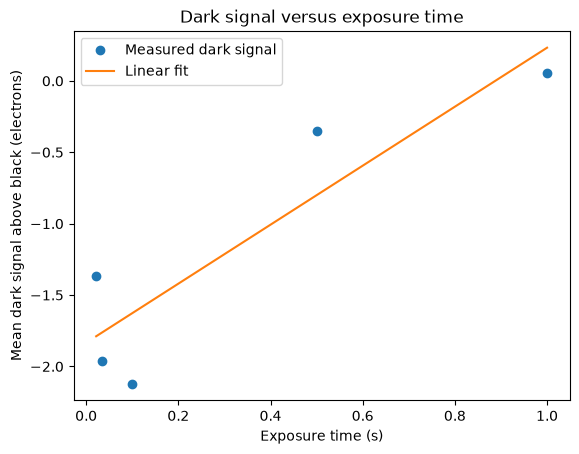

Dark-current fit: 2.066 e-/pixel/s


In [185]:
import importlib
import tifffile
importlib.reload(utils)

darkExposureSeconds = []
darkSignalElectrons = []
conversionGainElectronPerDN = reportFitResults["conversionGainElectronPerDN"]

for imagePath in darkImagePaths:
    with rawpy.imread(str(imagePath)) as raw:
        greenPlane = raw.raw_image_visible[0::2, 1::2].astype(float)
        greenBlackLevelDN = float(raw.black_level_per_channel[1])
        meanGreenDN = float(greenPlane.mean())

    with tifffile.TiffFile(imagePath) as dng:
        exposureNumerator, exposureDenominator = (
            dng.pages[0].tags["ExifTag"].value["ExposureTime"]
        )
    exposureTimeSeconds = exposureNumerator / exposureDenominator
    darkSignalDN = meanGreenDN - greenBlackLevelDN
    darkSignalElectrons.append(darkSignalDN * conversionGainElectronPerDN)
    darkExposureSeconds.append(exposureTimeSeconds)
    print(
        f"{imagePath.name}: {exposureTimeSeconds:.4f} s, "
        f"{darkSignalDN:.3f} DN above black"
    )

darkCurrentResults = utils.plot_dark_current(
    darkExposureSeconds,
    darkSignalElectrons,
)
plt.savefig('images/d11.png')
plt.show()
darkCurrentElectronsPerSecond = darkCurrentResults["darkCurrentElectronsPerSecond"]
print(f"Dark-current fit: {darkCurrentElectronsPerSecond:.3f} e-/pixel/s")
if darkCurrentElectronsPerSecond <= 0:
    print("No positive dark-current slope is resolved above the black-level/noise variation.")

## Part 5

### D12

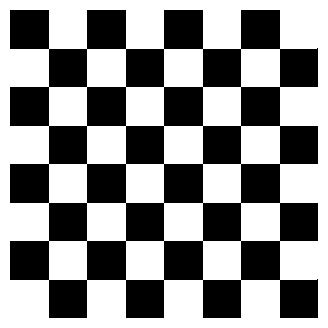

Mean of encoded sRGB pixels: 0.500000
sRGB code that displays the mean linear-light value: 0.735357


In [130]:
checkerHeight, checkerWidth = 256, 256
checkerSize = 32
rowIndices, columnIndices = np.indices((checkerHeight, checkerWidth))
checkerboardSrgb = (
    (rowIndices // checkerSize + columnIndices // checkerSize) % 2
).astype(float)


encodedMean = float(checkerboardSrgb.mean())

linearCheckerboard = psu.srgb_to_linear(checkerboardSrgb)
linearLightMean = float(linearCheckerboard.mean())
correctDisplayCode = float(psu.linear_to_srgb(linearLightMean))

plt.figure(figsize=(4, 4))
plt.imshow(checkerboardSrgb, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.axis("off")
plt.show()

print(f"Mean of encoded sRGB pixels: {encodedMean:.6f}")

print(
    "sRGB code that displays the mean linear-light value: "
    f"{correctDisplayCode:.6f}"
)

### D13

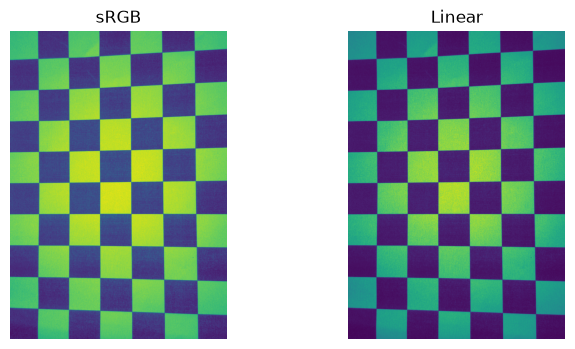

Mean of encoded sRGB pixels: 0.3888206194594742
sRGB encoding of mean linear light: 0.43542160285669484


In [186]:
greenDN = utils.find_checkerboard(imageFolder / "cb1.DNG").astype(np.float64)

with rawpy.imread(str(imageFolder / "cb1.DNG")) as raw:
    greenIndex = int(raw.raw_pattern[0, 1])
    blackLevel = raw.black_level_per_channel[greenIndex]
    whiteLevel = raw.white_level

greenLinear = np.clip(
    (greenDN - blackLevel) / (whiteLevel - blackLevel), 0, 1
)
greenSrgb = psu.linear_to_srgb(greenLinear)
#create a subplot 
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(greenSrgb)
plt.axis("off")
plt.title("sRGB")
plt.subplot(1, 2, 2)
plt.imshow(greenLinear)
plt.axis("off")
plt.title("Linear")
plt.savefig('images/d13.png')
plt.show()
print("Mean of encoded sRGB pixels:", greenSrgb.mean())
print("sRGB encoding of mean linear light:",
      psu.linear_to_srgb(greenLinear.mean()))